# IBGE favelas and urban communities, 2022

**Final file:** `datasets/communities/final.gpkg`, an English-field export of the preserved IBGE source. Layer `favelas_2022` contains 12,348 community polygons and original provider values in EPSG:4674. `field_dictionary` records the seven original field codes. Place names retain their original spelling.

**Input:** The preserved `data/processed/ibge/Data/favelas_2022.gpkg`.

**Process, in order:**
1. [Check the file](processing.py) against the inventoried size and SHA-256, GeoPackage integrity, EPSG:4674 and unique community IDs.
2. [Rename the seven fields](../english_export.py) in a checked copy and verify every source value, feature ID and geometry blob. No polygon is cleaned, reprojected or removed.

**Source note:** The file appears to derive from [IBGE's 2022 Favelas e Comunidades Urbanas product](https://www.ibge.gov.br/geociencias/organizacao-do-territorio/tipologias-do-territorio/15788-favelas-e-comunidades-urbanas.html?lang=pt-BR). The original project contains the same GeoPackage, and the [baseline inventory](https://github.com/fab1s/brazil-project/blob/archive/full-project-2026-10-27/docs/evidence/baseline-files.csv) records its checksum. No acquisition or conversion script was supplied, so this notebook starts from that preserved file.

In [1]:
DATASET = "communities"
from pathlib import Path
import os, sys, sqlite3
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "datasets/project.toml").is_file())
sys.path[:0] = [str(PROJECT / "datasets" / "shared"), str(PROJECT / "datasets"), str(PROJECT / "datasets" / DATASET)]
from processing import build, inspect_final
REBUILD = os.environ.get("BRAZIL_NOTEBOOK_REBUILD", "1") == "1"
print("Project:", PROJECT.name)
print("Mode:", "build from local inputs" if REBUILD else "preview existing verified local output")

Project: brazil-project
Mode: preview existing verified local output


## 1. Verify and export the source

The required local input is `data/processed/ibge/Data/favelas_2022.gpkg`. Its inventoried checksum is checked before making an independent copy. Seven provider field names become English names; original codes and place names remain as values, with their source field codes in `field_dictionary`. Every source value, feature ID and geometry blob is compared before publication. No newer IBGE release is acquired.


In [2]:
result = build(PROJECT) if REBUILD else inspect_final(PROJECT, preview=True)
display(pd.DataFrame([{"community polygons": result["features"],
                       "CRS": f"EPSG:{result['epsg']}"}]))
print("Local GeoPackage:", Path(result["file"]).relative_to(PROJECT))
print("SHA-256:", result["sha256"])

,community polygons,CRS
0,12348,EPSG:4674


Local GeoPackage: outputs/maps/notebook-exports/communities.gpkg
SHA-256: ab0a7bc510e6a9e4da9c6cdcd55d6cf3b1da9f1ba265aaf5a26c9fb519310d68


## 2. Inspect geographic coverage

These are **community features by reported state**, not population totals.

,state,communities
0,SP,3123
1,RJ,1724
2,PE,849
3,PA,723
4,CE,702
5,MG,653
6,PR,636
7,BA,572
8,ES,516
9,RS,481


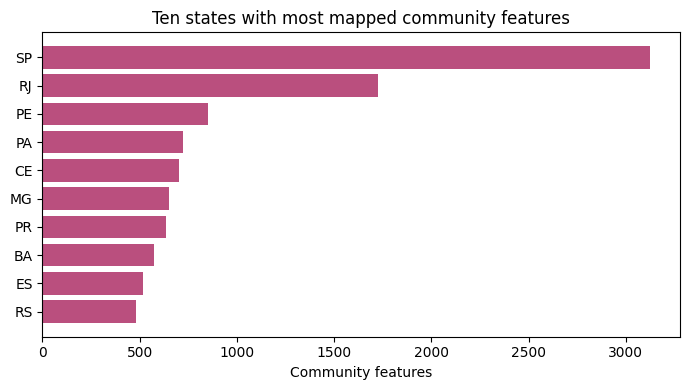

In [3]:
with sqlite3.connect(f"file:{result['file']}?mode=ro", uri=True) as db:
    states = pd.read_sql_query('SELECT state_abbreviation AS state, COUNT(*) AS communities FROM favelas_2022 GROUP BY state_abbreviation ORDER BY communities DESC', db)
display(states.head(12))
fig, ax = plt.subplots(figsize=(7, 4))
shown = states.head(10).iloc[::-1]
ax.barh(shown.state, shown.communities, color="#ba4f7e")
ax.set_xlabel("Community features")
ax.set_title("Ten states with most mapped community features")
fig.tight_layout()
display(fig)
plt.close(fig)

## 3. Check which IDs reached the frozen website tiles

The highest-zoom archive can repeat one source feature across several tiles, so compare **distinct source IDs**. This is an optional read-only check when the saved website archive is available locally; it does not establish equality of geometry or attributes.

In [4]:
from processing import website_id_check
website_ids = website_id_check(PROJECT)
display(pd.DataFrame([{
    "source IDs": website_ids.get("source_ids"),
    "website IDs": website_ids.get("website_ids"),
    "source IDs absent from tiles": len(website_ids.get("source_ids_absent_from_tiles", [])),
    "tile IDs absent from source": len(website_ids.get("website_ids_absent_from_source", [])),
}]))
print("Comparison:", website_ids)

,source IDs,website IDs,source IDs absent from tiles,tile IDs absent from source
0,12348,12348,0,0


Comparison: {'status': 'identifier comparison only', 'source_ids': 12348, 'website_ids': 12348, 'source_ids_absent_from_tiles': [], 'website_ids_absent_from_source': []}


**Limit:** All 12,348 source community IDs appear in the locally saved highest-zoom website tiles. This checks identifier coverage only; tile geometry is clipped and quantised, and full attribute/geometry parity has not been established.

## Verification and recovery

The export checks **12,348** unique community codes, EPSG:4674, GeoPackage integrity, every original field value and exact geometry blobs. `final.gpkg` now uses English field names and therefore has a new file checksum. A changed source, missing field or altered geometry stops publication. Restore the inventoried source and rerun the notebook if needed; no scientific cleaning or newer-release comparison has been claimed.

**Current export audit (2026-10-27):** `datasets/run.py communities` rebuilt the English copy from the inventoried input; `datasets/run.py handoff --output-dir PATH` copied it. The independent comparison passed for 12,348 source IDs, all seven original attribute values, EPSG:4674 and exact geometry blobs. Handoff SHA-256: `ab0a7bc510e6a9e4da9c6cdcd55d6cf3b1da9f1ba265aaf5a26c9fb519310d68`. Source names and values are recoverable through `field_dictionary`; place names were left as supplied. The frozen website tile comparison checks IDs only.
